In [1]:
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
import matplotlib
from astropy.table import Table, vstack, hstack, join
import fitsio
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
import pandas as pd

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['figure.titlesize'] = 16

In [3]:
def getFSFBGS(file,clusteringtab, zrange = [0.2,0.25]):
    '''
    Description
        Makes an Astropy table with certain columns from fastspecfit, selecting only galaxies that are also in clusteringtab
    Arguments
        file: FITS file to read from
        clusteringtab: Astropy table of BGS galaxies (must have at least TARGETID)
    Returns
        Astropy table of BGS galaxies
    '''
    #columns = ["TARGETID","ABSMAG01_SDSS_U","ABSMAG01_SDSS_G","ABSMAG01_SDSS_R","DN4000","LOGMSTAR"]
    columns = ["TARGETID","ABSMAG01_SDSS_R","LOGMSTAR"]
    tab2 = Table(fitsio.read(file,ext=2,columns=columns))
    columns = ["Z","RA","DEC"]
    tab1 = Table(fitsio.read(file,ext=1,columns=columns))
    tabbgs = hstack([tab1,tab2])
    tabbgs = tabbgs[(tabbgs['Z'] > zrange[0]) & (tabbgs['Z'] < zrange[1])]
    tabbgs = join(tabbgs,clusteringtab,keys="TARGETID")
    return tabbgs

In [4]:
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgs_clustering = vstack([bgsN,bgsS])


fsf_dir = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/'
files = []
#for i in range(12):
for i in range(12):
    files.append(fsf_dir + 'fastspec-loa-main-bright-nside1-hp'+f"{i:02}"+'.fits')
bgstabs = [getFSFBGS(file,bgs_clustering) for file in files]
tabbgs = vstack(bgstabs)

In [5]:
len(tabbgs)

1360952

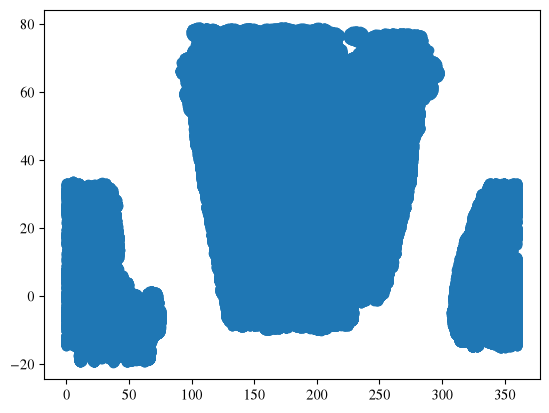

In [6]:
plt.scatter(tabbgs['RA'],tabbgs['DEC'])

In [7]:
def getnz(tab,zbins,effectivearea):
    solidanglefrac = effectivearea / 41253
    dists = cosmo.comoving_distance(np.array(zbins))/u.Mpc*cosmo.h   
    zmid = (zbins[1:]+zbins[:-1])/2
    sphere_vols = 4/3*np.pi*dists**3*solidanglefrac
    shell_vols = sphere_vols[1:]-sphere_vols[:-1]
    hist, bins = np.histogram(tab['Z'],bins=zbins,density=False)
    nz = hist/shell_vols
    return nz,zmid

In [8]:
cosmo.h

np.float64(0.6766)

In [9]:
bins = np.arange(0.2,0.25, step = 0.5)
effectivearea = 3610.678582723435 + 8500.358983202575 #from BGS n(z) table
hist,binsmed = getnz(tabbgs,bins,effectivearea)

bgs_stellarmasscut = tabbgs[tabbgs['LOGMSTAR'] > 10.7]
hist_smcut,binsmed = getnz(bgs_stellarmasscut,bins,effectivearea)

In [88]:
print(hist_smcut)

[0.00251105 0.00240289 0.00246936 0.00237814 0.00226341]


Text(0.5, 1.0, 'Number density of BGS Galaxies')

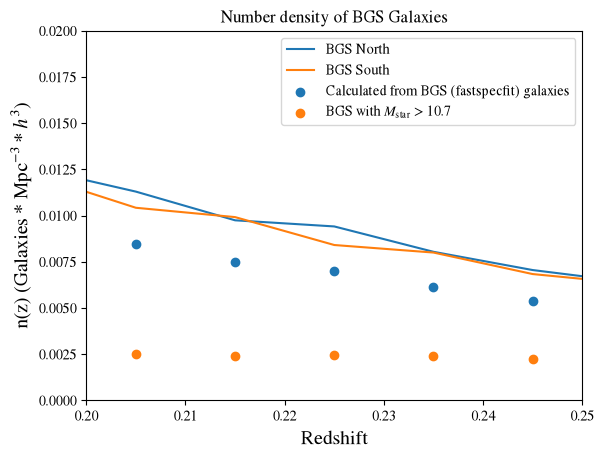

In [90]:
catalogdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
nz_north = pd.read_csv(catalogdir+"BGS_BRIGHT_NGC_nz.txt",skiprows=2,sep=r'\s+')
catalogdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
nz_south = pd.read_csv(catalogdir+"BGS_BRIGHT_SGC_nz.txt",skiprows=2,sep=r'\s+')
plt.plot(nz_north['#zmid'],nz_north['n(z)'],label='BGS North')
plt.plot(nz_south['#zmid'],nz_south['n(z)'],label='BGS South')
plt.scatter(binsmed,hist,label = "Calculated from BGS (fastspecfit) galaxies")
plt.scatter(binsmed,hist_smcut,label = r"BGS with $M_\text{star}$ > 10.7")
plt.xlim(0.2,0.25)
plt.ylim(0,0.02)
plt.legend()
plt.xlabel("Redshift")
plt.ylabel(r"n(z) (Galaxies * Mpc$^{-3}*h^{3}$)")

bgs_stellarmasscut = tabbgs[tabbgs['LOGMSTAR'] > 10.7]
plt.title("Number density of BGS Galaxies")


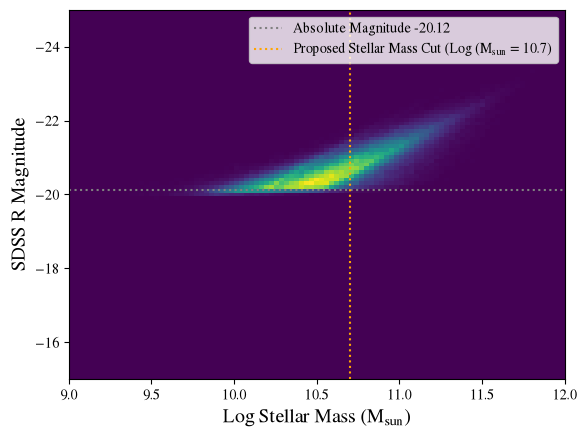

In [93]:
fig, ax = plt.subplots()

bgs_z0p24 = tabbgs[tabbgs['Z'] > 0.24]
plt.hist2d(bgs_z0p24['LOGMSTAR'],bgs_z0p24['ABSMAG01_SDSS_R'],
           bins = [np.linspace(9,12,num=100),np.linspace(-25,-15,num=100)])
ax.invert_yaxis()
plt.ylabel("SDSS R Magnitude")
plt.xlabel(r"Log Stellar Mass (M$_\text{sun}$)")
plt.plot([9,12],[-20.12,-20.12],linestyle='dotted',color = 'gray',label = "Absolute Magnitude -20.12")
#plt.plot([10.5,10.5],[-15,-25],linestyle='dotted',color = 'red',label = "Proposed Stellar Mass Cut 2")
plt.plot([10.7,10.7],[-15,-25],linestyle='dotted',color = 'orange',label = r"Proposed Stellar Mass Cut (Log (M$_\text{sun}$ = 10.7)")
plt.legend()

In [42]:
import astropy.units as u
from astropy.coordinates import Distance
import numpy as np

# Given apparent magnitude and distance (in parsecs)
m = 19.5 * u.mag
d = cosmo.luminosity_distance(0.24) * cosmo.h

# Calculate distance modulus: 5 * log10(d / 10 pc)
dist_modulus = 5 * np.log10(d.to(u.pc).value / 10.0)

# Calculate absolute magnitude
M = m.value - dist_modulus
print(f"Absolute Magnitude: {M}")

Absolute Magnitude: -20.122794316224443


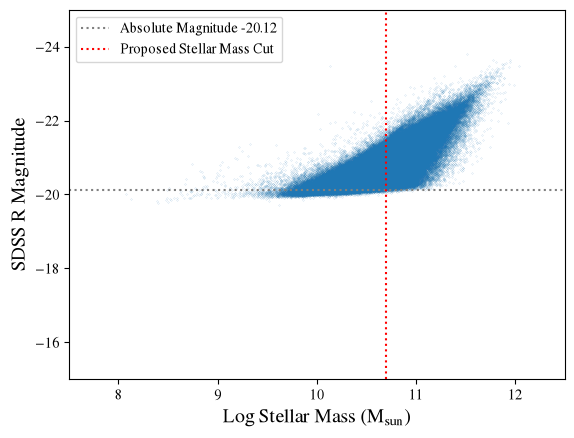

In [49]:
fig, ax = plt.subplots()
plt.scatter(bgs_z0p24['LOGMSTAR'],bgs_z0p24['ABSMAG01_SDSS_R'],s=0.005)
plt.xlim(7.5,12.5)
ax.invert_yaxis()
plt.ylim(-15,-25)
plt.ylabel("SDSS R Magnitude")
plt.xlabel(r"Log Stellar Mass (M$_{\text{sun}}$)")
plt.plot([7.5,12.5],[-20.12,-20.12],linestyle='dotted',color = 'gray',label = "Absolute Magnitude -20.12")
plt.plot([10.7,10.7],[-15,-25],linestyle='dotted',color = 'red',label = "Proposed Stellar Mass Cut")
plt.legend()

In [13]:
len(tabbgs)
print(len(tabbgs[tabbgs['LOGMSTAR'] > 10.25])/len(tabbgs))
print(len(tabbgs[tabbgs['LOGMSTAR'] > 10.5])/len(tabbgs))

0.6366278715838115
0.4202615413576437


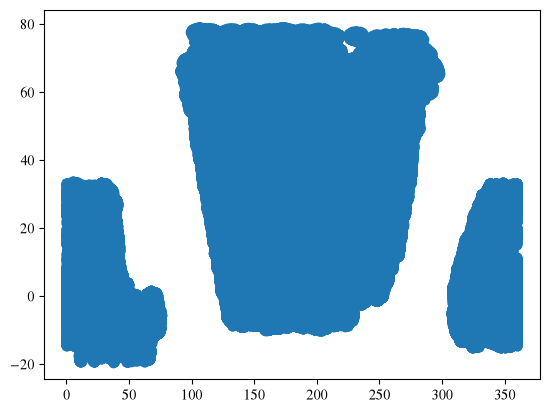

In [14]:
plt.scatter(tabbgs['RA'],tabbgs['DEC'])

In [15]:
catalogdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
nz = pd.read_csv(catalogdir+"BGS_BRIGHT_NGC_nz.txt",skiprows=2,sep=r'\s+')

(0.0, 0.02)

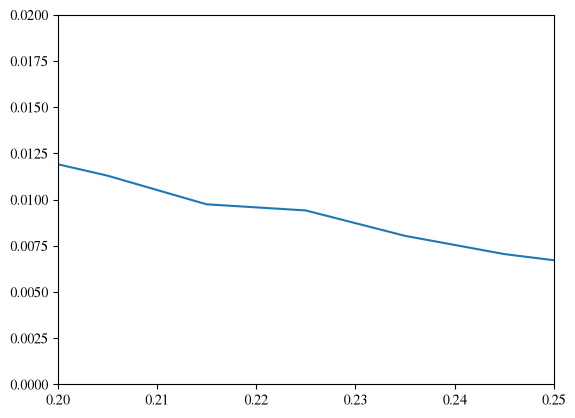

In [16]:
plt.plot(nz['#zmid'],nz['n(z)'])
plt.xlim(0.2,0.25)
plt.ylim(0,0.02)